In [4]:
# Importing Libraries
import pandas as pd
from sklearn.tree import DecisionTreeRegressor
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

In [5]:
# Loading The Dataset
print("Loading The Dataset...")
df=pd.read_csv('jobs_dataset.csv')
print("Dataset loaded successfully! Shape:", df.shape)

Loading The Dataset...
Dataset loaded successfully! Shape: (735, 14)


In [6]:
df.head()

,company,rating,location,positionName,description,salary,url,jobType/0,jobType/1,jobType/2,jobType/3,searchInput/country,searchInput/position,externalApplyLink
0,Google,4.3,"San Bruno, CA","Senior Data Scientist, Research, YouTube Search",Note: By applying to this position you will ha...,"$166,000 - $244,000 a year",https://www.indeed.com/viewjob?jk=3129ec5dde24...,Full-time,NaN,NaN,NaN,US,Data Scientist,https://www.google.com/about/careers/applicati...
1,BAXTER,3.7,"Milwaukee, WI 53214",Senior AI Engineer - Data Scientist,This is where you save and sustain lives\n\nAt...,"$112,000 - $154,000 a year",https://www.indeed.com/viewjob?jk=19da1b85455c...,Full-time,NaN,NaN,NaN,US,Data Scientist,https://jobs.baxter.com/en/job/-/-/152/8298788...
2,Meta,4.2,"Redmond, WA","Audio Software Engineer, Applied Scientist","Redmond, WA • + 2 more•Full Time\nMessenger\nM...",$70.67 an hour,https://www.indeed.com/viewjob?jk=0b0b432e2a51...,Full-time,NaN,NaN,NaN,US,Data Scientist,https://www.metacareers.com/jobs/3101204833367...
3,Meta,4.2,"Bellevue, WA 98005","Software Engineer, Machine Learning","Bellevue, WA • Full Time\nMeta\nSoftware Engin...","$203,350 - $240,240 a year",https://www.indeed.com/viewjob?jk=08d2ef77c976...,Full-time,NaN,NaN,NaN,US,Data Scientist,https://www.metacareers.com/jobs/1096352489054...
4,Lockheed Martin,4.0,"Shelton, CT 06484",AI / Machine Learning Research Engineer (early...,"Job ID: 694362BR\nDate posted: May. 22, 2025\n...",NaN,https://www.indeed.com/viewjob?jk=e9aad7dcc34e...,Full-time,NaN,NaN,NaN,US,Data Scientist,https://click.appcast.io/t/V35efAz0-l7FWwo6IKe...


In [7]:
df.describe()

,rating
count,735.000000
mean,3.232109
std,1.357551
min,0.000000
25%,3.300000
50%,3.700000
75%,4.000000
max,5.000000


In [24]:
#Data Cleaning
# Drop rows with missing values in 'salary'
df=df.dropna(subset=["salary"])
# Extract numeric value from text string and convert to float
df["salary_num"]= df["salary"].str.extract(r"\$(\d+,?\d*)")[0].str.replace(",","").astype(float)
# Drop extraction failures and create a clean copy
df=df.dropna(subset=["salary_num"]).copy()
print("Salary column cleaned successfully! new shape:",df.shape)

Salary column cleaned successfully! new shape: (506, 15)


In [11]:
print(df.columns)

Index(['company', 'rating', 'location', 'positionName', 'description',
       'salary', 'url', 'jobType/0', 'jobType/1', 'jobType/2', 'jobType/3',
       'searchInput/country', 'searchInput/position', 'externalApplyLink',
       'salary_num'],
      dtype='object')


In [19]:
# 3. Defining Features (X) and Target (y)
X_text = df[["company", "rating", "location", "positionName"]].copy()
Y = df["salary_num"]

In [14]:
# check missing value
print(df.isnull().sum())

company                   0
rating                    0
location                  0
positionName              0
description               0
salary                    0
url                       0
jobType/0               157
jobType/1               494
jobType/2               505
jobType/3               505
searchInput/country       0
searchInput/position      0
externalApplyLink       117
salary_num                0
dtype: int64


In [15]:
# 4. Handling Missing Values in 'rating' using the median
X_text["rating"] = X_text["rating"].fillna(X_text["rating"].median())
print("Features and Target defined, and missing ratings handled!")

Features and Target defined, and missing ratings handled!


In [18]:
# 5. One-Hot Encoding
X = pd.get_dummies (X_text, columns=["company", "location", "positionName"], drop_first=True)
print("Data prepared! Features (X) shape after encoding:", X.shape)

Data prepared! Features (X) shape after encoding: (506, 889)


In [20]:
# 6. Model Building & Training
print("Training the model...")
model = DecisionTreeRegressor(max_depth=5, random_state=42)
model.fit(X, Y)
print("Model trained successfully!")

Training the model...
Model trained successfully!


In [21]:
# 7. Making Predictions & Comparing with Actual Values
predictions = model.predict(X.head(4))

print("\n--- Predictions vs. Actual Salaries ---")
comparison_df = pd.DataFrame(
    {"Predicted Salary": predictions, "Actual Salary": y.head(4).values}
)
display(comparison_df)


--- Predictions vs. Actual Salaries ---


,Predicted Salary,Actual Salary
0,148939.621849,166000.0
1,125663.323077,112000.0
2,70.000000,70.0
3,101703.000000,203350.0


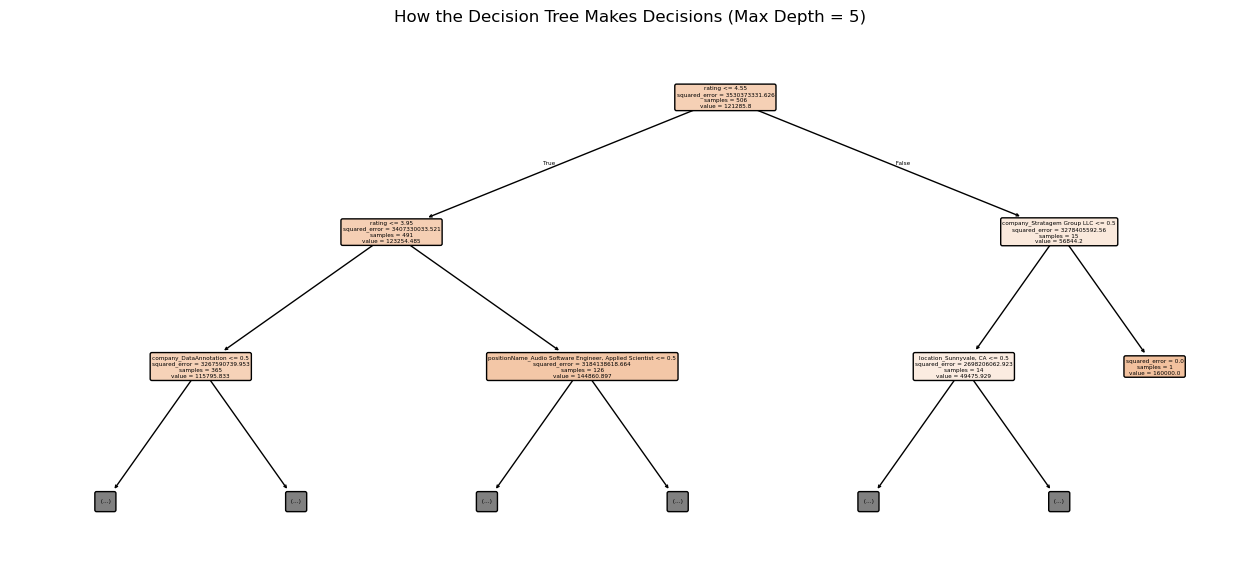

In [23]:
# 8. Visualizing the Decision Tree
plt.figure(figsize=(16, 7))
plot_tree(model,max_depth=2,feature_names=X.columns,filled=True,rounded=True,)
plt.title("How the Decision Tree Makes Decisions (Max Depth = 5)")
plt.show()